# 01 — Data Audit


In [60]:
import hashlib
import os
import sys

sys.path.append('..')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

from src.dataset import average_hash, md5_hash, scan_all_images

DATA_ROOT='../data/raw/dataset'
os.listdir(DATA_ROOT)


['test', 'train', 'unclean']

In [18]:
os.listdir(os.path.join(DATA_ROOT , 'train'))

['ambulance',
 'autobus',
 'kamyun',
 'kamyunet',
 'minibus',
 'savari',
 'taxi',
 'vanet']

In [19]:

os.listdir(os.path.join(DATA_ROOT , 'unclean'))

['ambulance',
 'autobus',
 'kamyun',
 'kamyunet',
 'minibus',
 'neysan',
 'savari',
 'taxi',
 'vanet']

In [31]:
def count_classes(split_path):
    counts= {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join (split_path , class_name)
        if os.path.isdir(class_dir):
            counts[class_name] = len(os.listdir(class_dir))
    return counts

train_count = count_classes (os.path.join(DATA_ROOT , 'train'))
print(train_count)

{'ambulance': 219, 'autobus': 245, 'kamyun': 250, 'kamyunet': 238, 'minibus': 230, 'savari': 250, 'taxi': 250, 'vanet': 250}


In [33]:
def count_classes(split_path):
    counts= {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join (split_path , class_name)
        if os.path.isdir(class_dir):
            counts[class_name] = len(os.listdir(class_dir))
    return counts

unclean_count = count_classes (os.path.join(DATA_ROOT , 'unclean'))
print(unclean_count)

{'ambulance': 157, 'autobus': 226, 'kamyun': 246, 'kamyunet': 221, 'minibus': 185, 'neysan': 250, 'savari': 250, 'taxi': 243, 'vanet': 250}


In [22]:
train_classes = set (train_count.keys())
unclean_classes = set (unclean_count.keys())

print("train:" , train_classes - unclean_classes)
print("unclean:" , unclean_classes - train_classes)
print("both:" , train_classes & unclean_classes)


train: set()
unclean: {'neysan'}
both: {'ambulance', 'minibus', 'kamyun', 'kamyunet', 'autobus', 'savari', 'vanet', 'taxi'}


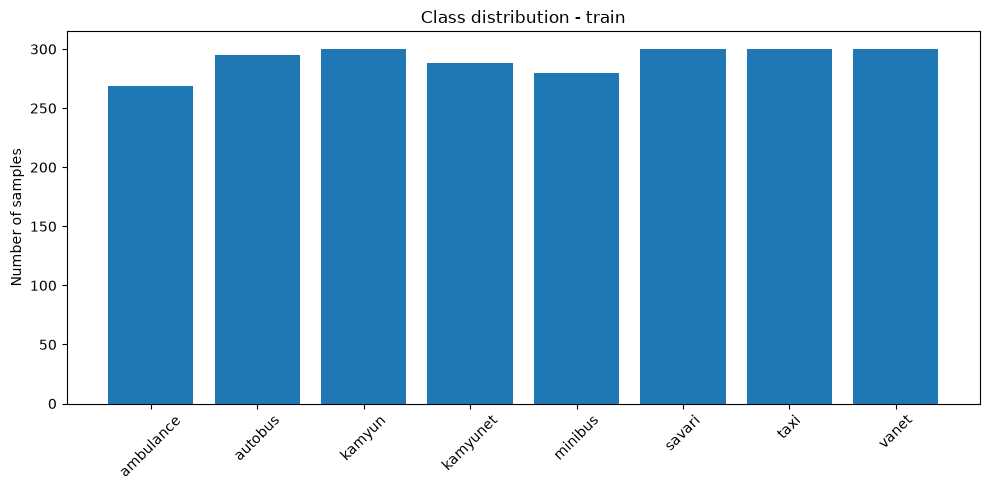

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(train_count.keys(), train_count.values())
plt.xticks(rotation=45)
plt.title('Class distribution - train')
plt.ylabel('Number of samples')
plt.tight_layout()
plt.show()


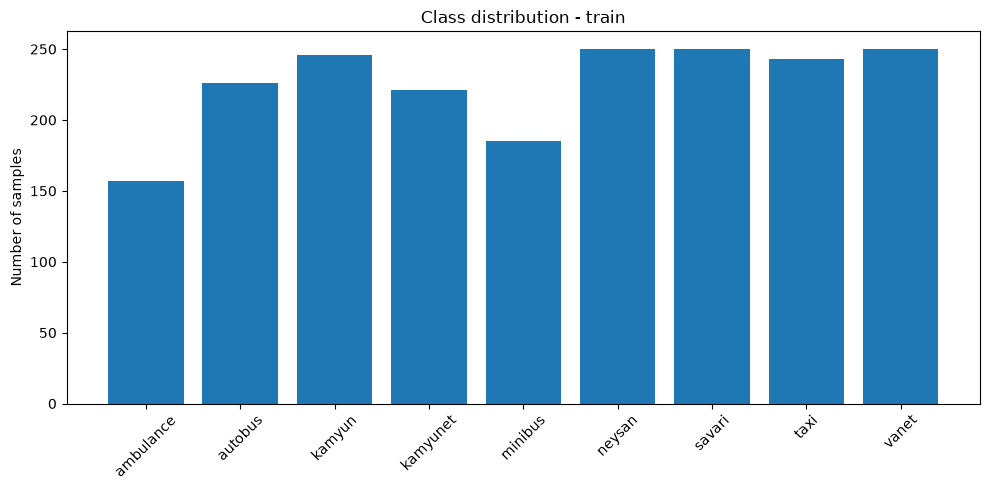

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(unclean_count.keys(), unclean_count.values())
plt.xticks(rotation=45)
plt.title('Class distribution - train')
plt.ylabel('Number of samples')
plt.tight_layout()
plt.show()

In [59]:
df=scan_all_images(DATA_ROOT)
print(f"All scanned photos:{len(df)}")

md5_dupes = df [df.duplicated(subset='md5' , keep=False)]. sort_values('md5')
print(f"Duplicate groups with md5 : {md5_dupes['md5'].nunique()}")

avghash_dupes=df[df.duplicated(subset='avghash' , keep=False)].sort_values('avghash')
print(f"Duplicate groups with avghash: {avghash_dupes['avghash'].nunique()}")

def check_label_conflicts(dupes_df , hash_col):
    conflict = []
    for h , group in dupes_df.groupby(hash_col):
        if group['class'].nunique()>1:
            conflict.append(group)
    return conflict

md5_conflicts = check_label_conflicts(md5_dupes , 'md5')
avghash_conflicts=check_label_conflicts(avghash_dupes , 'avghash')
print(f"\nGroups with label conflicts(md5) :{len(md5_conflicts)}")
print(f"\nGroups with label conflicts(avghash): {len(avghash_conflicts)}")




hashing images:   0%|          | 0/4360 [00:00<?, ?it/s]

hashing images: 100%|██████████| 4360/4360 [00:07<00:00, 615.73it/s]

All scanned photos:4360
Duplicate groups with md5 : 24
Duplicate groups with avghash: 46

Groups with label conflicts(md5) :1

Groups with label conflicts(avghash): 8


In [54]:
counts_by_split_class = df.groupby(['split', 'class']).size().reset_index(name='count')
print(counts_by_split_class.to_string())

print("\n--- جمع کل هر split ---")
print(df.groupby('split').size())

      split      class  count
0      test  ambulance     50
1      test    autobus     50
2      test     kamyun     50
3      test   kamyunet     50
4      test    minibus     50
5      test     savari     50
6      test       taxi     50
7      test      vanet     50
8     train  ambulance    219
9     train    autobus    245
10    train     kamyun    250
11    train   kamyunet    238
12    train    minibus    230
13    train     savari    250
14    train       taxi    250
15    train      vanet    250
16  unclean  ambulance    157
17  unclean    autobus    226
18  unclean     kamyun    246
19  unclean   kamyunet    221
20  unclean    minibus    185
21  unclean     neysan    250
22  unclean     savari    250
23  unclean       taxi    243
24  unclean      vanet    250

--- جمع کل هر split ---
split
test        400
train      1932
unclean    2028
dtype: int64



MD5 conflict group :
____________________________________________________________________________________________________


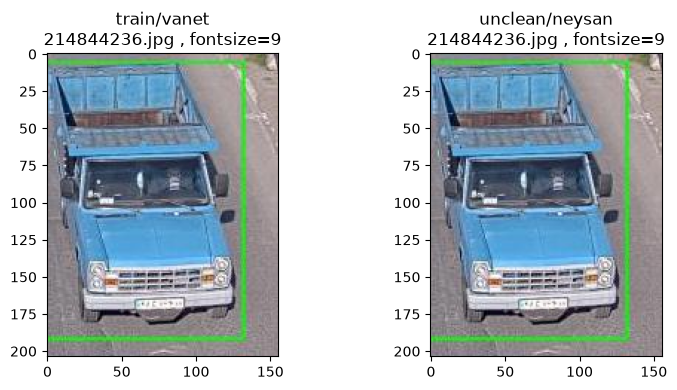


 Average Hash conflicts:
____________________________________________________________________________________________________


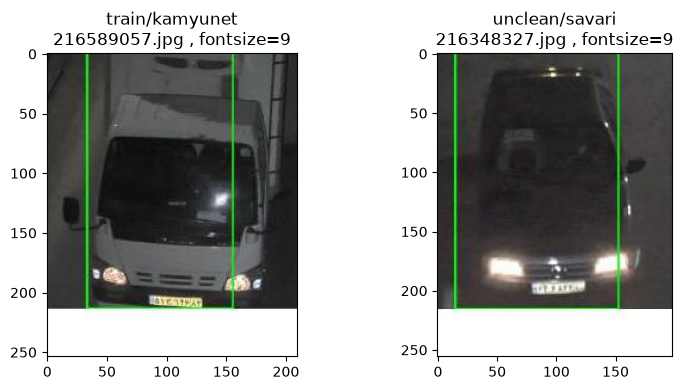


 Average Hash conflicts:
____________________________________________________________________________________________________


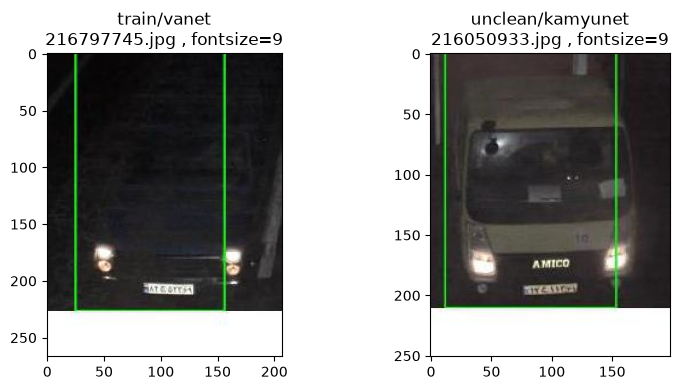


 Average Hash conflicts:
____________________________________________________________________________________________________


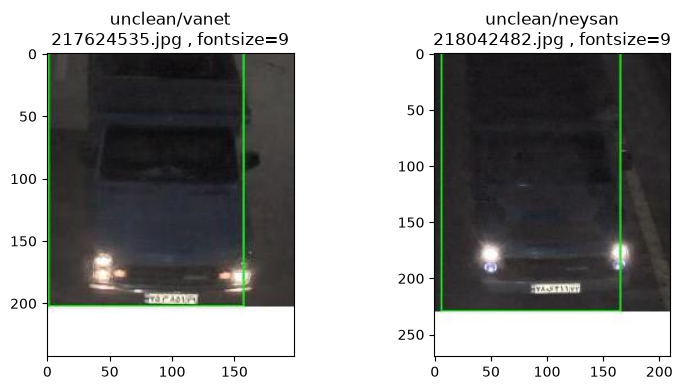


 Average Hash conflicts:
____________________________________________________________________________________________________


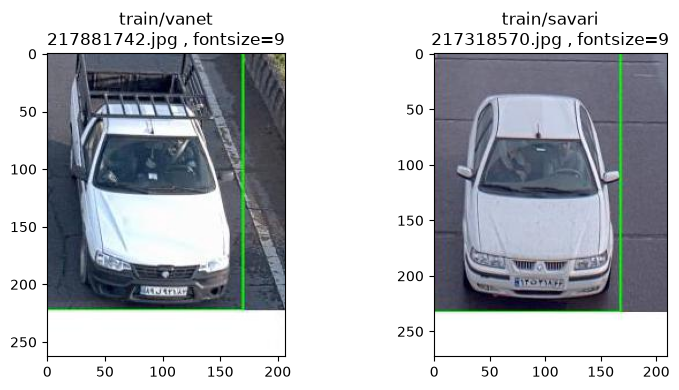


 Average Hash conflicts:
____________________________________________________________________________________________________


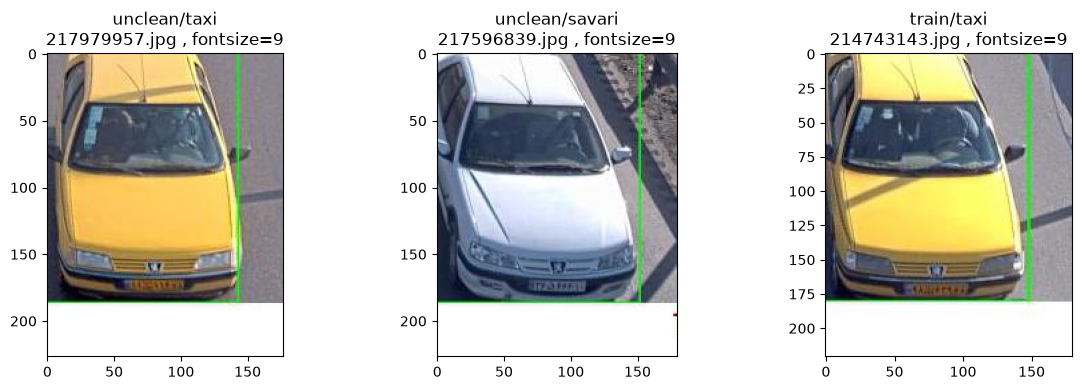


 Average Hash conflicts:
____________________________________________________________________________________________________


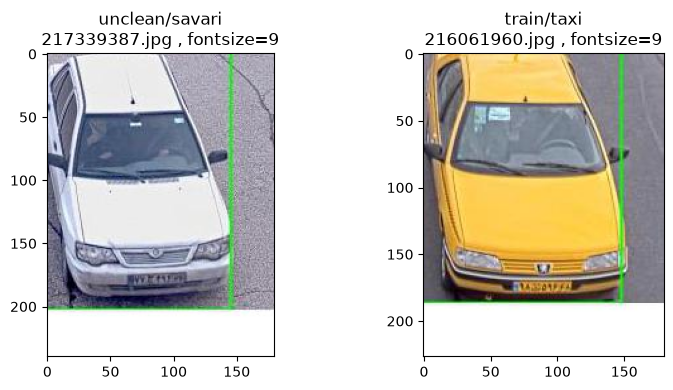


 Average Hash conflicts:
____________________________________________________________________________________________________


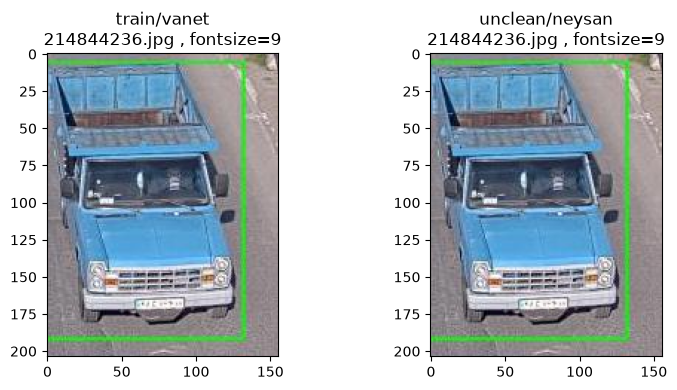


 Average Hash conflicts:
____________________________________________________________________________________________________


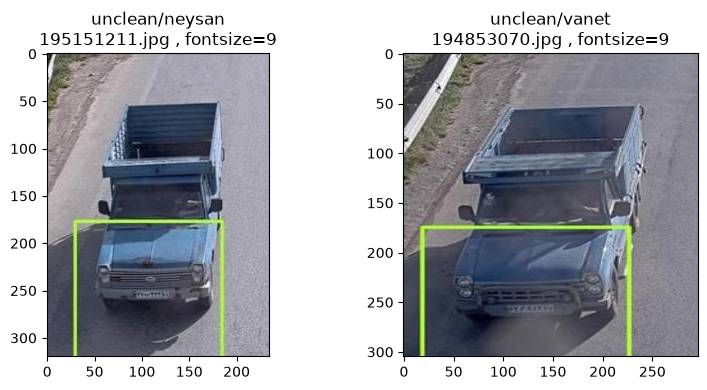

In [53]:
def show_conflict_group(conflict_groups , group_index=0):
    group = conflict_groups[group_index]
    n = len(group)
    fig , axes = plt.subplots(1 , n , figsize=(4*n , 4))
    if n == 1:
        axes = [axes]
    for ax , (_, row) in zip (axes, group.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"{row['split']}/{row['class']}\n{row['filename']} , fontsize=9")
    plt.tight_layout()
    plt.show()

print("\nMD5 conflict group :")
print("_" * 100)
show_conflict_group(md5_conflicts , group_index=0)

for i in range(len(avghash_conflicts)):
    print("\n Average Hash conflicts:")
    print("_" * 100)
    show_conflict_group(avghash_conflicts , group_index= i)